In [1]:
import jax, jax.numpy as jnp, numpy as np, scipy.optimize
import matplotlib.pyplot as plt
import gebtaero_jax as gx

AIREX = gx.IsoMaterial(66e6, 0.32, 80.0)
T300 = gx.OrthoMaterial(181e9, 10.3e9, 0.28, 7.17e9, 1600.0)
chord, span, n_el = 0.2, 0.4, 12
air = gx.FlightCondition(rho=1.225)

def section(angles):
    lam = gx.Laminate.from_plies([gx.Ply(T300, 0.125e-3, angles[0]), gx.Ply(AIREX, 2e-3, 0.0), gx.Ply(T300, 0.125e-3, angles[1])])
    return gx.CrossSection.composite_plate(chord, lam)

def build(angles, V):
    m = gx.straight_wing(section(angles), span, chord, 0.0, n_el, aero=gx.Aero.PETERS)
    return m, air.replace(velocity=V)

## Sweep of the upper ply angle (lower ply fixed at −45°), as in the original example

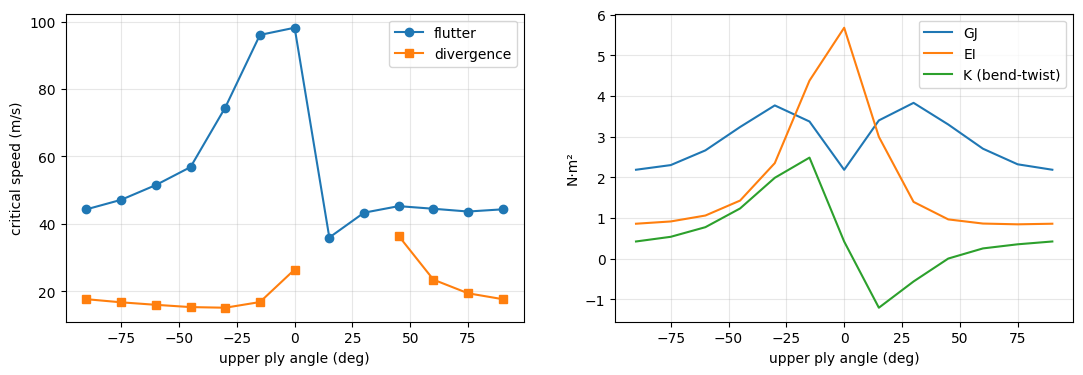

In [2]:
oris = np.arange(-90, 91, 15)
res = []
for o in oris:
    m, _ = build((-45.0, float(o)), 0.0)
    S = np.linalg.pinv(np.asarray(section((-45.0, float(o))).flexibility))
    pf = gx.flutter_speed(m, air, 1.0, 150.0, n_grid=30)
    pd = gx.divergence_speed(m, air, 1.0, 150.0, n_grid=30)
    res.append((o, pf.velocity, pd.velocity, pf.frequency_hz, S[3, 3], S[4, 4], S[3, 4]))
res = np.array(res)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(res[:, 0], res[:, 1], "o-", label="flutter"); axs[0].plot(res[:, 0], res[:, 2], "s-", label="divergence")
axs[0].set_xlabel("upper ply angle (deg)"); axs[0].set_ylabel("critical speed (m/s)"); axs[0].legend(); axs[0].grid(alpha=.3)
axs[1].plot(res[:, 0], res[:, 4], label="GJ"); axs[1].plot(res[:, 0], res[:, 5], label="EI"); axs[1].plot(res[:, 0], res[:, 6], label="K (bend-twist)")
axs[1].set_xlabel("upper ply angle (deg)"); axs[1].set_ylabel("N·m²"); axs[1].legend(); axs[1].grid(alpha=.3);

The bend–twist coupling `K` drives wash-in (K > 0: bending up twists the nose up, lowering divergence) or wash-out.

## Exact gradient of the flutter speed w.r.t. both ply angles

In [3]:
angles = jnp.array([-45.0, 30.0])
r = gx.flutter_speed_and_grad(build, angles, 1.0, 150.0, n_grid=30)
print(r.point, "\n dV_f/d(angles) =", np.asarray(r.dV_dparams), "m/s per degree")
h = 1e-3
for i in range(2):
    e = np.zeros(2); e[i] = h
    vp = gx.flutter_speed(*build(np.asarray(angles) + e, 0.0), 1.0, 150.0, n_grid=30, tol=1e-9).velocity
    vm = gx.flutter_speed(*build(np.asarray(angles) - e, 0.0), 1.0, 150.0, n_grid=30, tol=1e-9).velocity
    print(f" finite difference ply {i}: {(vp - vm) / (2 * h):.6f}")

CriticalPoint(flutter: V=43.3112 m/s, f=41.3385 Hz) 
 dV_f/d(angles) = [0.56456539 0.29205382] m/s per degree


 finite difference ply 0: 0.564565


 finite difference ply 1: 0.292054


## Gradient-based tailoring
The sweep shows the classical trade-off: **wash-in** (K > 0, bending up twists the nose up) produces low divergence
speeds, while **wash-out** (K < 0) suppresses divergence but changes the flutter mode. Maximising
`min(V_f, V_d)` directly is ill-posed for a gradient method (divergence appears/disappears from the speed range).
A smooth formulation is:

$$\max_{\theta_1, \theta_2} V_f(\theta_1, \theta_2) \quad \text{s.t.} \quad K(\theta_1, \theta_2) \le -K_{min}$$

where the bend–twist coupling `K` comes straight from the CLT section model and is differentiated with `jax.grad`,
and `dV_f/dθ` comes from `flutter_speed_and_grad`. A small wash-out margin (K_min = 0.3 N·m²) is needed because the
aerodynamic centre (quarter chord) lies ahead of the mid-chord reference axis, so K = 0 still allows divergence.

In [4]:
K_of = lambda a: jnp.linalg.pinv(section(a).flexibility)[3, 4]
K_fun, K_grad = jax.jit(K_of), jax.jit(jax.grad(K_of))
K_min = 0.3

cache = {}
def vf(a):
    key = tuple(np.round(a, 8))
    if key not in cache:
        r = gx.flutter_speed_and_grad(build, jnp.asarray(a), 1.0, 200.0, n_grid=30)
        cache[key] = (r.point.velocity, np.asarray(r.dV_dparams))
    return cache[key]

history = [(np.array([-45.0, 30.0]), vf(np.array([-45.0, 30.0]))[0])]
opt = scipy.optimize.minimize(
    lambda a: -vf(a)[0], history[0][0], jac=lambda a: -vf(a)[1], method="SLSQP", bounds=[(-90, 90)] * 2,
    constraints=[{"type": "ineq", "fun": lambda a: -K_min - float(K_fun(jnp.asarray(a))),
                  "jac": lambda a: -np.asarray(K_grad(jnp.asarray(a)))}],
    callback=lambda a: history.append((a.copy(), vf(a)[0])), options={"maxiter": 20, "ftol": 1e-4})
print(opt.message)
for name, a in [("start", history[0][0]), ("optimum", opt.x)]:
    m, _ = build(a, 0.0)
    pd = gx.divergence_speed(m, air, 1.0, 200.0, n_grid=30)
    print(f"{name:<8s} plies = ({a[0]:7.2f}°, {a[1]:7.2f}°)  K = {float(K_fun(jnp.asarray(a))):6.3f} N·m²  "
          f"V_f = {vf(a)[0]:6.2f} m/s  V_d = {f'{pd.velocity:.2f}' if pd.found else '> 200'} m/s")

Optimization terminated successfully
start    plies = ( -45.00°,   30.00°)  K = -0.564 N·m²  V_f =  43.31 m/s  V_d = > 200 m/s


optimum  plies = ( -29.24°,   24.43°)  K = -0.300 N·m²  V_f =  50.28 m/s  V_d = 61.34 m/s


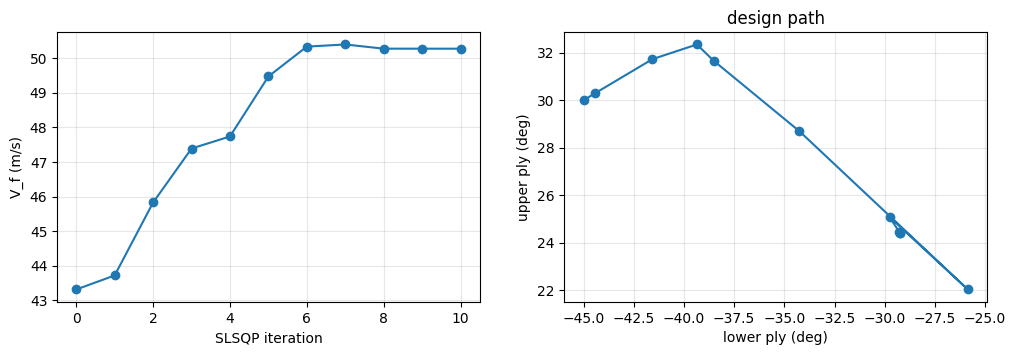

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot([h[1] for h in history], "o-"); ax[0].set_xlabel("SLSQP iteration"); ax[0].set_ylabel("V_f (m/s)"); ax[0].grid(alpha=.3)
path = np.array([h[0] for h in history])
ax[1].plot(path[:, 0], path[:, 1], "o-"); ax[1].set_xlabel("lower ply (deg)"); ax[1].set_ylabel("upper ply (deg)")
ax[1].set_title("design path"); ax[1].grid(alpha=.3);